# VISTA: tải và phân tích media trên Colab T4

**Mục tiêu:** đọc metadata của train và validation; chọn mẫu validation đa dạng theo venue; tải MP4 có giới hạn dung lượng; kiểm tra video/audio thực; nghe/nhìn mẫu và nhận dạng lời nói ngắn bằng GPU T4. Đây là EDA và kiểm tra khả thi, **chưa phải benchmark chất lượng tóm tắt**. Không tải video hoặc đọc abstract của test.

1. Mở notebook bằng Google Colab, chọn **Runtime → Change runtime type → T4 GPU**.
2. Dùng tài khoản Hugging Face **đã được VISTA cấp quyền**, tạo Colab Secret tên `HF_TOKEN` (bật notebook access), hoặc nhập token ở ô kín khi được hỏi. Phiên đăng nhập Chrome không tự chuyển sang Colab.
3. Chạy lần lượt các ô. Mặc định lưu vào `MyDrive/VISTA_EDA`; sửa `TARGET_VIDEOS` và `MAX_DOWNLOAD_GB` ở ô cấu hình trước khi chạy. Chạy lại sẽ dùng tệp đã có.

Nguồn: [VISTA dataset card](https://huggingface.co/datasets/dongqi-me/VISTA/blob/main/README.md); [Hugging Face download API](https://huggingface.co/docs/huggingface_hub/package_reference/file_download).

In [1]:
%pip -q install -U huggingface_hub pandas matplotlib pillow openai-whisper
import shutil, subprocess
assert shutil.which('ffprobe') and shutil.which('ffmpeg'), 'Colab cần FFmpeg/ffprobe'
import torch
print('CUDA:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 34.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 838.0/838.0 kB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 111.1 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 105.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 114.5 MB/s eta 0:00:0000:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
diffusers 0.40.0

In [2]:
from pathlib import Path
from getpass import getpass
import hashlib, json, os, re, time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from huggingface_hub import HfApi, hf_hub_download

REPO_ID = 'dongqi-me/VISTA'
TARGET_VIDEOS = 40          # số ứng viên validation tối đa
MAX_DOWNLOAD_GB = 4.0      # ngân sách byte MP4 trong lượt này
RUN_ASR = True             # dùng T4 nhận dạng đoạn âm thanh đầu video
ASR_VIDEOS = 5
ASR_SECONDS = 60
USE_DRIVE = True
assert TARGET_VIDEOS > 0 and MAX_DOWNLOAD_GB > 0
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = Path('/content/drive/MyDrive/VISTA_EDA')
else:
    OUT = Path('/content/VISTA_EDA')
MEDIA = OUT / 'videos' / 'val'
MEDIA.mkdir(parents=True, exist_ok=True)
try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
except Exception:
    token = None
if not token:
    token = getpass('HF_TOKEN (không hiển thị): ')
assert token, 'Thiếu HF_TOKEN'
api = HfApi(token=token)
print('HF account:', api.whoami(token=token)['name'])
REVISION = api.repo_info(REPO_ID, repo_type='dataset', token=token).sha
print('VISTA revision:', REVISION)

Mounted at /content/drive
HF account: anhdavang
VISTA revision: 39c60afff185fbefe80b685898cf073da0fd92ab


## 1. Metadata toàn bộ train và validation

    Chỉ tải ba file JSON nhỏ. Biểu đồ toàn bộ corpus dưới đây là **metadata**, không phải media đã xác minh. `test.json` được giữ nguyên chưa mở.

train_part1.json: reconstructing file:   0%|          |  0.00B / 12.9MB            

train_part1.json: downloading bytes:           |  0.00B            

train_part1 records= 8000 columns= ['id', 'title', 'authors', 'abstract', 'video_file', 'video_path', 'paper_url', 'venue']


train_part2.json: reconstructing file:   0%|          |  0.00B / 11.1MB            

train_part2.json: downloading bytes:           |  0.00B            

train_part2 records= 6881 columns= ['id', 'title', 'authors', 'abstract', 'video_file', 'video_path', 'paper_url', 'venue']


val.json:   0%|          | 0.00/2.99M [00:00<?, ?B/s]

val records= 1859 columns= ['id', 'title', 'authors', 'abstract', 'video_file', 'video_path', 'paper_url', 'venue']


,records,unique_ids,missing_abstract,abstract_words_median,venues
split,,,,,
train_part1,8000,8000,0,165.0,20
train_part2,6881,6881,0,166.0,19
val,1859,1859,0,165.0,19


,records
venue,
NEURIPS 2023,2548
NEURIPS 2022,2389
NEURIPS 2021,1895
NEURIPS 2020,1629
ICML 2023,1099
ICML 2021,1040
ACL 2023,920
EMNLP 2023,896
EMNLP 2021,737


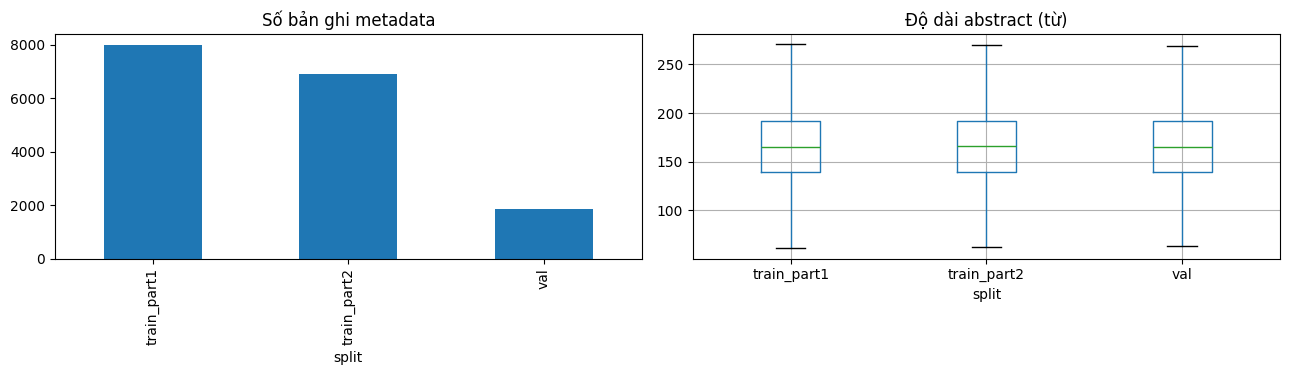

In [3]:
def read_records(path):
    obj = json.loads(Path(path).read_text(encoding='utf-8'))
    if isinstance(obj, list):
        return obj
    if isinstance(obj, dict):
        for key in ('data', 'samples', 'items', 'videos'):
            if isinstance(obj.get(key), list):
                return obj[key]
        if all(isinstance(v, dict) for v in obj.values()):
            return list(obj.values())
    raise ValueError(f'Không nhận diện được cấu trúc JSON: {path}')

tables = {}
for split in ('train_part1', 'train_part2', 'val'):
    path = hf_hub_download(REPO_ID, f'{split}.json', repo_type='dataset', revision=REVISION, token=token)
    tables[split] = pd.DataFrame(read_records(path))
    print(split, 'records=', len(tables[split]), 'columns=', list(tables[split].columns))
meta = pd.concat([df.assign(split=split) for split, df in tables.items()], ignore_index=True)
for col in ('id', 'title', 'abstract', 'venue'):
    if col not in meta:
        meta[col] = None
meta['abstract_words'] = meta['abstract'].fillna('').astype(str).str.split().str.len()
meta['title_words'] = meta['title'].fillna('').astype(str).str.split().str.len()
summary = meta.groupby('split').agg(records=('split','size'), unique_ids=('id','nunique'),
    missing_abstract=('abstract', lambda s: s.fillna('').eq('').sum()),
    abstract_words_median=('abstract_words','median'), venues=('venue','nunique'))
display(summary)
display(meta['venue'].fillna('unknown').value_counts().head(20).rename_axis('venue').to_frame('records'))
fig, axes = plt.subplots(1, 2, figsize=(13,4))
meta.groupby('split').size().plot.bar(ax=axes[0], title='Số bản ghi metadata')
meta.boxplot(column='abstract_words', by='split', ax=axes[1], showfliers=False)
axes[1].set_title('Độ dài abstract (từ)'); fig.suptitle(''); plt.tight_layout(); plt.show()

## 2. Chọn cohort validation và dự toán tải

    Chọn vòng tròn qua các venue, có thứ tự cố định theo SHA-256 của ID. Đây là mẫu EDA có chủ đích để kiểm tra nhiều venue; không đại diện thống kê cho toàn VISTA. In bảng chọn và tổng byte **trước khi tải**.

In [4]:
val = tables['val'].copy()
assert {'id','video_file'}.issubset(val.columns), 'Metadata thiếu id hoặc video_file; kiểm tra schema trước khi chọn'
val['video_file'] = val['video_file'].astype(str).map(lambda s: Path(s).name)
val = val[val['video_file'].str.endswith('.mp4', na=False)].copy()
val['venue_group'] = val.get('venue', pd.Series(index=val.index, dtype='object')).fillna('unknown').astype(str)
val['order_key'] = val['id'].astype(str).map(lambda s: hashlib.sha256(s.encode()).hexdigest())
assert val['video_file'].is_unique, 'Trùng video_file trong validation'
buckets = {k: g.sort_values('order_key').to_dict('records') for k,g in val.groupby('venue_group')}
chosen = []
while len(chosen) < TARGET_VIDEOS and any(buckets.values()):
    for venue in sorted(buckets):
        if buckets[venue] and len(chosen) < TARGET_VIDEOS:
            chosen.append(buckets[venue].pop(0))
cohort = pd.DataFrame(chosen)
cohort['hub_path'] = cohort['video_file'].map(lambda s: f'videos/val/{s}')
files = {item.path: item for item in api.list_repo_tree(REPO_ID, path_in_repo='videos/val',
    repo_type='dataset', revision=REVISION, recursive=False, token=token) if hasattr(item,'size')}
cohort['expected_bytes'] = cohort['hub_path'].map(lambda s: files[s].size if s in files else None)
assert cohort['expected_bytes'].notna().all(), 'Một số MP4 không có trong VISTA revision đã ghim'
budget = int(MAX_DOWNLOAD_GB * (1024**3))
cohort['cumulative_bytes'] = cohort['expected_bytes'].cumsum()
cohort = cohort[cohort['cumulative_bytes'] <= budget].copy()
assert len(cohort), 'Không có video nào nằm trong ngân sách. Tăng MAX_DOWNLOAD_GB.'
cols = ['id','venue_group','video_file','expected_bytes']
display(cohort[cols].head(15))
print('Đã chọn:',len(cohort),'video; dự toán:',round(cohort.expected_bytes.sum()/1024**3,2),'GiB; venue:',cohort.venue_group.nunique())
cohort[cols + ['hub_path']].to_csv(OUT/'selection.csv',index=False)

,id,venue_group,video_file,expected_bytes
0,val_1215,ACL 2021,2021.acl-long.569.mp4,36759760
1,val_1164,ACL 2022,2022.acl-long.591.mp4,25461524
2,val_1806,ACL 2023,2023.acl-long.795.mp4,7801739
3,val_0171,EACL 2023,2023.eacl-main.148.mp4,123020598
4,val_0507,EACL 2024,2024.eacl-long.36.mp4,89699193
5,val_1740,EMNLP 2021,2021.emnlp-main.545.mp4,29935705
6,val_0072,EMNLP 2023,2023.emnlp-main.457.mp4,164711688
7,val_1060,FINDINGS 2021,2021.findings-emnlp.346.mp4,11746806
8,val_1137,FINDINGS 2022,2022.findings-naacl.126.mp4,7138560
9,val_1119,FINDINGS 2023,2023.findings-acl.213.mp4,185381266


Đã chọn: 40 video; dự toán: 2.99 GiB; venue: 19


## 3. Tải media có resume và ghi receipt

    Mỗi tệp được tải bằng API chính thức ở revision cố định. Tệp đã có chỉ được bỏ qua khi kích thước khớp; lỗi riêng từng tệp được ghi vào CSV. Không in token.

In [5]:
receipts = []
for i, row in enumerate(cohort.itertuples(index=False), 1):
    dest = MEDIA / row.video_file
    start = time.monotonic()
    try:
        if dest.exists() and dest.stat().st_size == int(row.expected_bytes):
            status = 'cached'
        else:
            if dest.exists():
                dest.unlink()  # chỉ xóa tệp local sai kích thước trong thư mục VISTA_EDA
            dest = Path(hf_hub_download(REPO_ID, row.hub_path, repo_type='dataset',
                revision=REVISION, token=token, local_dir=OUT))
            status = 'downloaded'
        assert dest.stat().st_size == int(row.expected_bytes), 'size_mismatch'
        error = ''
    except Exception as exc:
        # Exception strings can contain signed CDN URLs; never persist them.
        status, error = 'failed', type(exc).__name__
    receipt = {'id':str(row.id), 'hub_path':row.hub_path, 'status':status,
        'expected_bytes':int(row.expected_bytes), 'actual_bytes':dest.stat().st_size if dest.exists() else 0,
        'seconds':round(time.monotonic()-start,1), 'error':error}
    receipts.append(receipt)
    pd.DataFrame(receipts).to_csv(OUT/'download_receipts.csv',index=False)
    print(f'{i}/{len(cohort)} {row.video_file}: {status} ({receipt["seconds"]} s)', error)
print(pd.DataFrame(receipts).status.value_counts())

videos/val/2021.acl-long.569.mp4: reconstructing file:   0%|          |  0.00B / 36.8MB            

videos/val/2021.acl-long.569.mp4: downloading bytes:           |  0.00B            

1/40 2021.acl-long.569.mp4: downloaded (2.5 s) 


videos/val/2022.acl-long.591.mp4: reconstructing file:   0%|          |  0.00B / 25.5MB            

videos/val/2022.acl-long.591.mp4: downloading bytes:           |  0.00B            

2/40 2022.acl-long.591.mp4: downloaded (2.1 s) 


... (110 outputs left out)

39/40 2021.acl-long.24.mp4: downloaded (2.4 s) 


videos/val/2022.acl-long.536.mp4: reconstructing file:   0%|          |  0.00B / 21.8MB            

videos/val/2022.acl-long.536.mp4: downloading bytes:           |  0.00B            

40/40 2022.acl-long.536.mp4: downloaded (2.2 s) 
status
downloaded    40
Name: count, dtype: int64


## 4. Phân tích video và audio thực

    `ffprobe` đọc duration, codec, độ phân giải, fps, audio sample rate. Ba ảnh tại 15%, 50%, 85% video cho biết nội dung thị giác; đoạn đầu 60 giây dùng `silencedetect` để thấy vùng âm thanh yên tĩnh. Các số này là **mô tả media**, không phải điểm chất lượng tóm tắt.

2021.acl-long.569.mp4 ok 12.6 min
2022.acl-long.591.mp4 ok 9.5 min
2023.acl-long.795.mp4 ok 5.9 min
2023.eacl-main.148.mp4 ok 11.7 min
2024.eacl-long.36.mp4 ok 12.0 min
2021.emnlp-main.545.mp4 ok 11.2 min
2023.emnlp-main.457.mp4 ok 6.0 min
2021.findings-emnlp.346.mp4 ok 2.7 min
2022.findings-naacl.126.mp4 ok 4.6 min
2023.findings-acl.213.mp4 ok 6.0 min
2024.findings-eacl.82.mp4 ok 12.6 min
10497-icml-2021.mp4 ok 5.0 min
24796-icml-2023.mp4 ok 4.2 min
2021.naacl-main.425.mp4 ok 11.3 min
2022.naacl-main.156.mp4 ok 4.6 min
18488-neurips-2020.mp4 ok 3.4 min
27375-neurips-2021.mp4 ok 11.5 min
53611-neurips-2022.mp4 ok 6.6 min
74164-neurips-2023.mp4 ok 4.7 min
2021.acl-long.467.mp4 ok 10.4 min
2022.acl-long.45.mp4 ok 9.0 min
2023.acl-long.655.mp4 ok 6.0 min
2023.eacl-main.110.mp4 ok 12.1 min
2024.eacl-long.71.mp4 ok 10.1 min
2021.emnlp-main.391.mp4 ok 11.6 min
2023.emnlp-main.1010.mp4 ok 5.9 min
2021.findings-emnlp.157.mp4 ok 5.8 min
2022.findings-acl.26.mp4 ok 5.4 min
2023.findings-acl.106.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,40,40,val_1215,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
video_file,40,40,2021.acl-long.569.mp4,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,40,1,ok,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
error,40,1,,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration_s,40.0,NaN,NaN,NaN,454.690655,205.497912,3.0,297.040766,376.906667,672.32,793.84
video_codec,40,2,h264,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
width,40.0,NaN,NaN,NaN,1430.65,374.537907,764.0,1280.0,1280.0,1737.5,2560.0
height,40.0,NaN,NaN,NaN,815.9,203.21011,480.0,720.0,720.0,976.5,1440.0
fps,40.0,NaN,NaN,NaN,25.730163,1.870206,23.666667,25.0,25.0,25.001747,30.302974
audio_codec,40,2,aac,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,id,video_file,status,error,duration_s,video_codec,width,height,fps,audio_codec,sample_rate,audio_channels,silence_events_first_minute


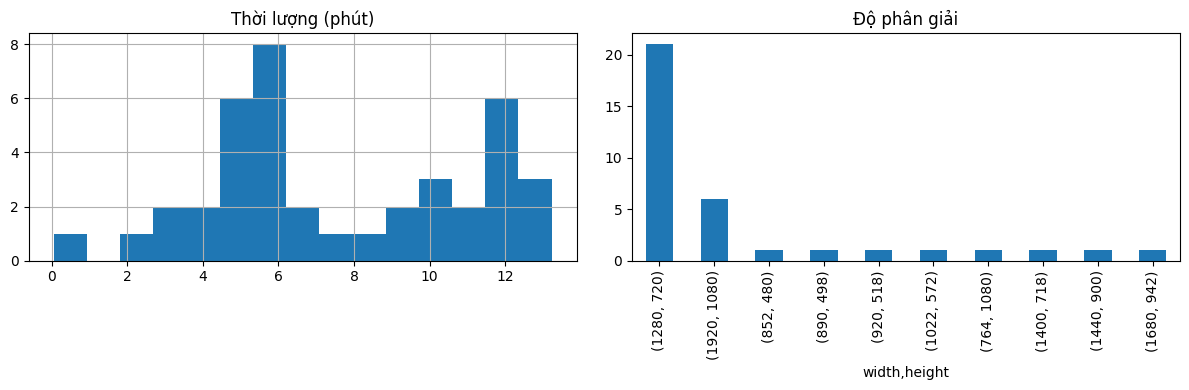

In [6]:
def probe(path):
    proc = subprocess.run(['ffprobe','-v','error','-show_format','-show_streams','-of','json',str(path)],
        capture_output=True,text=True,timeout=60,check=True)
    data = json.loads(proc.stdout)
    video = next((s for s in data['streams'] if s['codec_type']=='video'), {})
    audio = next((s for s in data['streams'] if s['codec_type']=='audio'), {})
    fps = video.get('avg_frame_rate','0/1')
    num, den = (float(x) for x in fps.split('/'))
    return {'duration_s':float(data['format'].get('duration',0)), 'video_codec':video.get('codec_name'),
        'width':video.get('width'), 'height':video.get('height'), 'fps':num/den if den else None,
        'audio_codec':audio.get('codec_name'), 'sample_rate':audio.get('sample_rate'),
        'audio_channels':audio.get('channels')}

def audio_silence_events(path, seconds=60):
    proc = subprocess.run(['ffmpeg','-nostdin','-hide_banner','-i',str(path),'-t',str(seconds),
        '-vn','-af','silencedetect=noise=-35dB:d=1','-f','null','-'], capture_output=True,text=True,timeout=120)
    return len(re.findall(r'silence_start:',proc.stderr)) if proc.returncode == 0 else None

media_rows=[]
for receipt in receipts:
    if receipt['status']=='failed':
        continue
    path = OUT / receipt['hub_path']
    try:
        stats=probe(path)
        stats['silence_events_first_minute']=audio_silence_events(path) if stats['audio_codec'] else None
        state='ok' if stats['duration_s']>0 and stats['video_codec'] and stats['audio_codec'] else 'missing_stream'
        error=''
    except Exception as exc:
        stats={}; state='probe_failed'; error=type(exc).__name__
    media_rows.append({'id':receipt['id'],'video_file':path.name,'status':state,'error':error,**stats})
    pd.DataFrame(media_rows).to_csv(OUT/'media_profile.csv',index=False)
    print(path.name,state,round(stats.get('duration_s',0)/60,1),'min')
media_df=pd.DataFrame(media_rows, columns=['id','video_file','status','error','duration_s',
    'video_codec','width','height','fps','audio_codec','sample_rate','audio_channels',
    'silence_events_first_minute'])
if len(media_df):
    display(media_df.describe(include='all').T)
    display(media_df[media_df.status!='ok'])
else:
    print('Không có media tải thành công; xem download_receipts.csv')
if len(media_df) and media_df.duration_s.notna().any():
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    media_df.duration_s.dropna().div(60).hist(ax=axs[0],bins=15);axs[0].set_title('Thời lượng (phút)')
    media_df.groupby(['width','height']).size().sort_values(ascending=False).head(10).plot.bar(ax=axs[1]);axs[1].set_title('Độ phân giải')
    plt.tight_layout();plt.show()

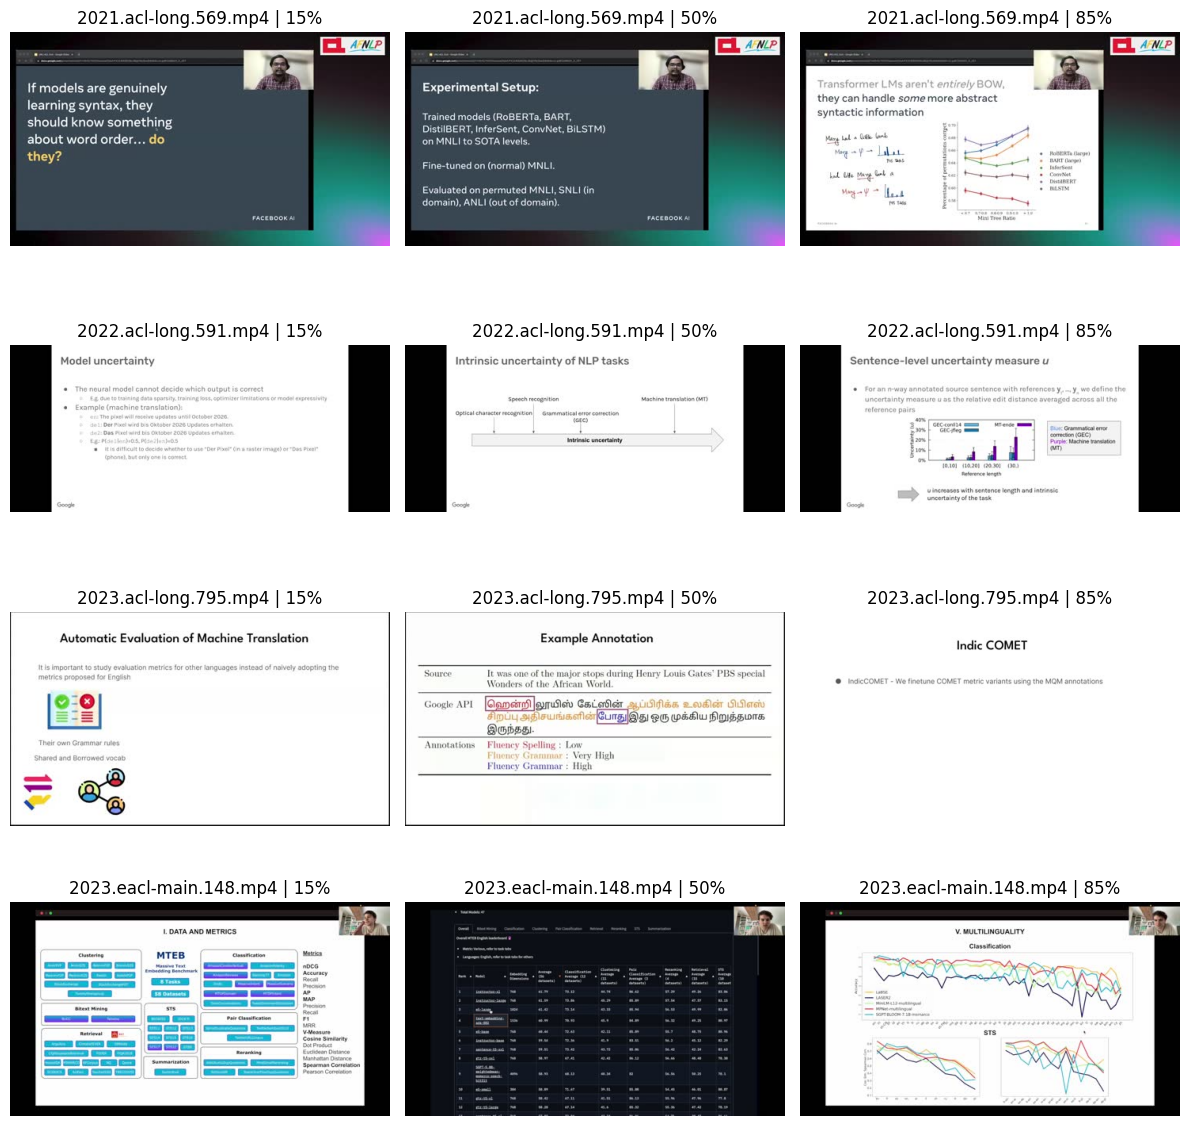

In [7]:
from PIL import Image
good = media_df[media_df.status=='ok'].head(4)
if good.empty:
    print('Chưa có MP4 hợp lệ để hiển thị frame')
else:
    fig, axes = plt.subplots(len(good), 3, figsize=(12,max(3,3*len(good))))
    if len(good)==1: axes=[axes]
    for row_axes, row in zip(axes, good.itertuples(index=False)):
        path=MEDIA/row.video_file
        for ax, fraction in zip(row_axes,(.15,.5,.85)):
            second=max(0, float(row.duration_s)*fraction)
            proc=subprocess.run(['ffmpeg','-nostdin','-v','error','-ss',str(second),'-i',str(path),
                '-frames:v','1','-vf','scale=480:-1','-f','image2pipe','-vcodec','mjpeg','-'],
                capture_output=True,timeout=90)
            if proc.returncode==0 and proc.stdout:
                from io import BytesIO
                ax.imshow(Image.open(BytesIO(proc.stdout)))
            ax.set_title(f'{row.video_file} | {fraction:.0%}'); ax.axis('off')
    plt.tight_layout();plt.show()

## 5. ASR mẫu ngắn trên T4

    Whisper `base.en` chỉ đọc **60 giây đầu** của tối đa 5 video để xem có lời nói và ngôn ngữ phù hợp. Transcript mẫu không thay thế transcript đầy đủ, cũng không được dùng để chấm tóm tắt. Nếu chỉ cần EDA media, đặt `RUN_ASR=False` ở ô cấu hình.

In [8]:
asr_rows=[]
if RUN_ASR and media_df.status.eq('ok').any() and torch.cuda.is_available():
    import whisper
    model=whisper.load_model('base.en',device='cuda' if torch.cuda.is_available() else 'cpu')
    for row in media_df[media_df.status=='ok'].head(ASR_VIDEOS).itertuples(index=False):
        path=MEDIA/row.video_file
        wav=Path('/content')/f'vista_asr_{hashlib.sha256(row.video_file.encode()).hexdigest()[:12]}.wav'
        try:
            subprocess.run(['ffmpeg','-nostdin','-y','-v','error','-i',str(path),'-t',str(ASR_SECONDS),
                '-vn','-ac','1','-ar','16000',str(wav)],check=True,timeout=120)
            result=model.transcribe(str(wav),fp16=torch.cuda.is_available(),language='en')
            asr_rows.append({'id':row.id,'video_file':row.video_file,'seconds':ASR_SECONDS,
                'transcript_excerpt':result['text'][:1200],'status':'ok'})
        except Exception as exc:
            asr_rows.append({'id':row.id,'video_file':row.video_file,'status':'failed','error':type(exc).__name__})
        finally:
            wav.unlink(missing_ok=True)
        pd.DataFrame(asr_rows).to_csv(OUT/'asr_sample.csv',index=False)
    display(pd.DataFrame(asr_rows))
else:
    print('ASR bỏ qua: đã tắt, không có MP4 hợp lệ, hoặc chưa chọn T4 GPU')

100%|███████████████████████████████████████| 139M/139M [00:02<00:00, 68.0MiB/s]


,id,video_file,seconds,transcript_excerpt,status
0,val_1215,2021.acl-long.569.mp4,60,"Hello, ACL. Welcome to the talk of our paper,...",ok
1,val_1164,2022.acl-long.591.mp4,60,"Hi, I will talk about the paper and certainty...",ok
2,val_1806,2023.acl-long.795.mp4,60,"Hi everyone, this is Ananya and Wignesh prese...",ok
3,val_0171,2023.eacl-main.148.mp4,60,"In this video, I'll present the massive text ...",ok
4,val_0507,2024.eacl-long.36.mp4,60,"Hi, welcome to the EACL 24 presentation on GA...",ok


## 6. Kết luận EDA và tệp bàn giao

    Xem tỷ lệ tải thành công, độ dài video, audio/video stream, phân bố venue và các lỗi. `selection.csv`, `download_receipts.csv`, `media_profile.csv`, `asr_sample.csv` được lưu trên Drive. Chỉ kết luận về cohort đã tải; không ngoại suy tỷ lệ truy cập cho toàn bộ 18.599 video.

In [9]:
report={
    'dataset':REPO_ID,'revision':REVISION,'scope':'train/val metadata + selected val media; test unopened',
    'metadata_records':{k:len(v) for k,v in tables.items()},
    'selection':{'target':TARGET_VIDEOS,'selected':len(cohort),'venues':int(cohort.venue_group.nunique()),
                 'planned_bytes':int(cohort.expected_bytes.sum())},
    'downloads':pd.DataFrame(receipts).status.value_counts().to_dict(),
    'media_status':media_df.status.value_counts().to_dict() if len(media_df) else {},
    'asr':{'requested':RUN_ASR,'completed':sum(r['status']=='ok' for r in asr_rows)},
}
(OUT/'eda_summary.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
print(json.dumps(report,indent=2,ensure_ascii=False))
print('Kết quả:',OUT)

{
  "dataset": "dongqi-me/VISTA",
  "revision": "39c60afff185fbefe80b685898cf073da0fd92ab",
  "scope": "train/val metadata + selected val media; test unopened",
  "metadata_records": {
    "train_part1": 8000,
    "train_part2": 6881,
    "val": 1859
  },
  "selection": {
    "target": 40,
    "selected": 40,
    "venues": 19,
    "planned_bytes": 3210108933
  },
  "downloads": {
    "downloaded": 40
  },
  "media_status": {
    "ok": 40
  },
  "asr": {
    "requested": true,
    "completed": 5
  }
}
Kết quả: /content/drive/MyDrive/VISTA_EDA


# Mở rộng: EDA toàn bộ VISTA validation (chưa thực thi)

Các ô 1–6 phía trên là **kết quả lịch sử của mẫu media giới hạn**, không chứng minh rằng toàn bộ validation đã được kiểm tra. Phần này duyệt **mọi bản ghi validation** ở cùng revision Hugging Face, lập manifest cho cả bản ghi thiếu media, kiểm tra media từng video, ghi lỗi theo ID và cập nhật độ phủ sau mỗi video. Chỉ dùng train/validation; không mở test. Để chạy EDA toàn tập, chạy ô cài thư viện ở đầu notebook rồi **nhảy thẳng tới phần này**; không cần chạy lại các ô tải mẫu 40 video. Đừng dùng ô kết luận cũ như kết luận của toàn tập.

Media chỉ nằm tạm ở `/content/vista_full_validation_work` trong lúc xử lý từng video; không đẩy bundle MP4 lên Drive. `full_val_manifest.csv`, `full_val_metadata_audit.csv`, `full_val_media_profile.csv`, `full_val_coverage.json` và `full_val_eda_summary.json` là tệp bàn giao. Sau khi chạy, chỉ coi EDA hoàn tất nếu `coverage_status == complete` và mọi ID đều có trạng thái cuối; lỗi media vẫn phải được xem xét trước khi dùng cohort cho benchmark.

In [ ]:
from pathlib import Path
from getpass import getpass
import hashlib, json, re, shutil, subprocess
import pandas as pd
import requests
from huggingface_hub import HfApi, hf_hub_download, hf_hub_url

REPO_ID = 'dongqi-me/VISTA'
PINNED_REVISION = '39c60afff185fbefe80b685898cf073da0fd92ab'
from google.colab import drive
drive.mount('/content/drive')
OUT = Path('/content/drive/MyDrive/VISTA_EDA')
try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
except Exception:
    token = None
if not token:
    token = getpass('HF_TOKEN (không hiển thị): ')
assert token, 'Thiếu HF_TOKEN'
api = HfApi(token=token)

FULL_DIR = OUT / 'full_validation'
FULL_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR = Path('/content/vista_full_validation_work')
TEMP_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = FULL_DIR / 'full_val_manifest.csv'
PROFILE_PATH = FULL_DIR / 'full_val_media_profile.csv'
COVERAGE_PATH = FULL_DIR / 'full_val_coverage.json'
SCOPE_PATH = FULL_DIR / 'scope.json'
if SCOPE_PATH.exists():
    scope = json.loads(SCOPE_PATH.read_text(encoding='utf-8'))
    assert scope['repo_id'] == REPO_ID and scope['split'] == 'val' and scope['test_accessed'] is False
    assert scope['revision'] == PINNED_REVISION, 'Scope Drive khác revision lịch sử; kiểm tra trước khi chạy tiếp'
    REVISION = PINNED_REVISION
else:
    REVISION = PINNED_REVISION
    scope = {'repo_id': REPO_ID, 'revision': REVISION, 'split': 'val', 'test_accessed': False}
    SCOPE_PATH.write_text(json.dumps(scope, indent=2), encoding='utf-8')
print('Pinned VISTA revision:', REVISION)

def read_records(path):
    obj = json.loads(Path(path).read_text(encoding='utf-8'))
    if isinstance(obj, list):
        return obj
    if isinstance(obj, dict):
        for key in ('data', 'samples', 'items', 'videos'):
            if isinstance(obj.get(key), list):
                return obj[key]
        if all(isinstance(v, dict) for v in obj.values()):
            return list(obj.values())
    raise ValueError(f'Không nhận diện được cấu trúc JSON: {path}')

tables = {}
for split in ('train_part1', 'train_part2', 'val'):
    source = hf_hub_download(REPO_ID, f'{split}.json', repo_type='dataset', revision=REVISION, token=token)
    tables[split] = pd.DataFrame(read_records(source))
    print(split, 'records:', len(tables[split]))

def probe(path):
    proc = subprocess.run(['ffprobe', '-v', 'error', '-show_format', '-show_streams', '-of', 'json', str(path)],
        capture_output=True, text=True, timeout=60, check=True)
    data = json.loads(proc.stdout)
    video = next((s for s in data['streams'] if s['codec_type'] == 'video'), {})
    audio = next((s for s in data['streams'] if s['codec_type'] == 'audio'), {})
    fps = video.get('avg_frame_rate', '0/1')
    num, den = (float(x) for x in fps.split('/'))
    return {'duration_s': float(data['format'].get('duration', 0)),
        'video_codec': video.get('codec_name'), 'width': video.get('width'),
        'height': video.get('height'), 'fps': num / den if den else None,
        'audio_codec': audio.get('codec_name'), 'sample_rate': audio.get('sample_rate'),
        'audio_channels': audio.get('channels')}

def audio_silence_events(path):
    proc = subprocess.run(['ffmpeg', '-nostdin', '-hide_banner', '-i', str(path), '-t', '60',
        '-vn', '-af', 'silencedetect=noise=-35dB:d=1', '-f', 'null', '-'],
        capture_output=True, text=True, timeout=120)
    return len(re.findall(r'silence_start:', proc.stderr)) if proc.returncode == 0 else None

full_val = tables['val'].copy()
assert {'id', 'video_file'}.issubset(full_val.columns), 'Thiếu id/video_file'
full_val['id'] = full_val['id'].fillna('').astype(str)
assert full_val['id'].ne('').all() and full_val['id'].is_unique, 'ID validation thiếu hoặc trùng'
full_val['video_file'] = full_val['video_file'].fillna('').astype(str)
# Không dùng basename để che đường dẫn không hợp lệ trong metadata.
def safe_val_path(value):
    path = value.replace('\\', '/')
    if path.startswith('videos/val/'):
        path = path[len('videos/val/'):]
    if not path or path.startswith('/') or '..' in path.split('/'):
        return ''
    name = Path(path).name
    return f'videos/val/{name}' if name.lower().endswith('.mp4') and name == path else ''

full_val['hub_path'] = full_val['video_file'].map(safe_val_path)
assert full_val.loc[full_val.hub_path.ne(''), 'hub_path'].is_unique, 'Trùng media path trong validation'
repo_files = {item.path: item for item in api.list_repo_tree(
    REPO_ID, path_in_repo='videos/val', repo_type='dataset',
    revision=REVISION, recursive=True, token=token) if hasattr(item, 'size')}
full_val['expected_bytes'] = full_val['hub_path'].map(
    lambda path: int(repo_files[path].size) if path in repo_files else None)
full_val['input_status'] = full_val.apply(
    lambda row: 'invalid_media_path' if not row.hub_path else
    ('missing_hub_file' if pd.isna(row.expected_bytes) else 'available'), axis=1)
manifest = full_val[['id', 'video_file', 'hub_path', 'expected_bytes', 'input_status']].copy()
manifest.insert(0, 'revision', REVISION)
manifest.to_csv(MANIFEST_PATH, index=False)
print('Validation records:', len(manifest), 'input statuses:', manifest.input_status.value_counts().to_dict())
display(manifest[manifest.input_status != 'available'].head(30))

## Phân tích nhãn, phân bố và giao nhau của toàn validation

    Bảng này dùng **toàn bộ metadata validation**. Giao train/validation dựa trên ID, tên media và tiêu đề chuẩn hóa; các giao nhau cần kiểm tra thủ công trước khi đánh giá. Không suy ra GT hợp lệ chỉ từ trường `abstract` có nội dung.

In [ ]:
train_meta = pd.concat([tables['train_part1'], tables['train_part2']], ignore_index=True)
def normalized_titles(frame):
    if 'title' not in frame:
        return set()
    return set(frame['title'].fillna('').astype(str).str.strip().str.casefold()) - {''}
def overlap(column):
    if column not in train_meta or column not in full_val:
        return None
    left = set(train_meta[column].fillna('').astype(str)) - {''}
    right = set(full_val[column].fillna('').astype(str)) - {''}
    return len(left & right)
label_stats = {
    'validation_records': len(full_val),
    'abstract_missing': int(full_val['abstract'].fillna('').astype(str).str.strip().eq('').sum()) if 'abstract' in full_val else None,
    'id_overlap_train': overlap('id'),
    'video_file_overlap_train': overlap('video_file'),
    'normalized_title_overlap_train': len(normalized_titles(train_meta) & normalized_titles(full_val)),
    'venues': int(full_val['venue'].nunique(dropna=True)) if 'venue' in full_val else None,
}
if 'abstract' in full_val:
    words = full_val['abstract'].fillna('').astype(str).str.split().str.len()
    label_stats['abstract_words'] = words.describe().to_dict()
    display(words.describe().to_frame('abstract_words'))
if 'venue' in full_val:
    display(full_val['venue'].fillna('missing').value_counts().to_frame('validation_records'))
audit = full_val[['id']].copy()
audit['venue'] = full_val['venue'].fillna('').astype(str) if 'venue' in full_val else ''
audit['abstract_words'] = words if 'abstract' in full_val else None
audit['missing_abstract'] = (words == 0) if 'abstract' in full_val else None
audit['id_overlap_train'] = audit['id'].isin(
    train_meta['id'].fillna('').astype(str)) if 'id' in train_meta else None
train_titles = normalized_titles(train_meta)
audit['title_overlap_train'] = full_val['title'].fillna('').astype(str).str.strip().str.casefold().isin(
    train_titles) if 'title' in full_val else None
audit.to_csv(FULL_DIR / 'full_val_metadata_audit.csv', index=False)
if 'abstract' in full_val:
    words.hist(bins=30, figsize=(8, 4), title='Từ trong abstract của toàn validation')
    import matplotlib.pyplot as plt
    plt.show()
display(audit[audit.missing_abstract.eq(True) | audit.id_overlap_train.eq(True) |
              audit.title_overlap_train.eq(True)].head(30))
print(json.dumps(label_stats, indent=2, ensure_ascii=False))

## Kiểm tra media từng video, có checkpoint và resume

    Mỗi video được tải qua URL của revision đã ghim vào ổ tạm Colab, kiểm tra kích thước và SHA-256 khi truyền, đọc ffprobe và vùng yên tĩnh 60 giây đầu, rồi xóa tệp tạm. Chạy lại sẽ bỏ qua ID đã có profile với cùng revision. Lỗi theo video được lưu để xử lý; không biến lỗi thành thành công. Cần đủ dung lượng tạm cho video lớn nhất và quyền Hugging Face đang hiệu lực.

In [ ]:
PROFILE_COLUMNS = ['revision', 'id', 'hub_path', 'status', 'error', 'expected_bytes',
    'actual_bytes', 'sha256', 'duration_s', 'video_codec', 'width', 'height', 'fps',
    'audio_codec', 'sample_rate', 'audio_channels', 'silence_events_first_minute']
if PROFILE_PATH.exists():
    profiles = pd.read_csv(PROFILE_PATH, dtype={'id': str}).fillna('')
    assert set(profiles['revision'].astype(str)) <= {REVISION}, 'Profile khác revision'
    assert profiles['id'].is_unique, 'Profile trùng ID'
    # Retry transient failures on resume; keep durable per-ID outcomes.
    profiles = profiles[~profiles.status.isin(['failed', 'insufficient_disk'])].to_dict('records')
else:
    profiles = []
done = {str(row['id']) for row in profiles}

def download_to_temp(hub_path, expected_bytes, dest):
    url = hf_hub_url(REPO_ID, hub_path, repo_type='dataset', revision=REVISION)
    digest = hashlib.sha256()
    actual = 0
    with requests.get(url, headers={'Authorization': f'Bearer {token}'}, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        with dest.open('wb') as out:
            for block in response.iter_content(chunk_size=4 * 1024 * 1024):
                if block:
                    out.write(block)
                    digest.update(block)
                    actual += len(block)
    if actual != expected_bytes:
        raise ValueError('size_mismatch')
    return actual, digest.hexdigest()

def write_coverage():
    frame = pd.DataFrame(profiles, columns=PROFILE_COLUMNS)
    frame.to_csv(PROFILE_PATH, index=False)
    counts = frame['status'].value_counts().to_dict() if len(frame) else {}
    completed = len(frame)
    summary = {**scope, 'total_validation_ids': len(manifest), 'profiled_ids': completed,
        'remaining_ids': len(manifest) - completed,
        'coverage_status': 'complete' if completed == len(manifest) else 'pending',
        'statuses': counts}
    COVERAGE_PATH.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
    return summary

write_coverage()
for index, row in enumerate(manifest.itertuples(index=False), 1):
    if row.id in done:
        continue
    result = {'revision': REVISION, 'id': row.id, 'hub_path': row.hub_path,
              'expected_bytes': row.expected_bytes, 'actual_bytes': 0, 'sha256': ''}
    temp = TEMP_DIR / (hashlib.sha256(row.id.encode()).hexdigest() + '.mp4')
    try:
        if row.input_status != 'available':
            result.update(status=row.input_status, error=row.input_status)
        elif int(row.expected_bytes) > shutil.disk_usage(TEMP_DIR).free:
            result.update(status='insufficient_disk', error='insufficient_disk')
        else:
            actual, sha = download_to_temp(row.hub_path, int(row.expected_bytes), temp)
            stats = probe(temp)
            stats['silence_events_first_minute'] = audio_silence_events(temp) if stats['audio_codec'] else None
            result.update(stats)
            result.update(actual_bytes=actual, sha256=sha,
                status='ok' if stats['duration_s'] > 0 and stats['video_codec'] and stats['audio_codec'] else 'missing_stream',
                error='')
    except Exception as exc:
        # Exception strings may include signed URLs or secrets.
        result.update(status='failed', error=type(exc).__name__)
    finally:
        temp.unlink(missing_ok=True)
    profiles.append(result)
    done.add(row.id)
    coverage = write_coverage()
    print(f'{index}/{len(manifest)} id={row.id} status={result["status"]} remaining={coverage["remaining_ids"]}')
print(json.dumps(write_coverage(), indent=2, ensure_ascii=False))

## Kết luận và giới hạn bằng chứng

    Chỉ `coverage_status: complete` cho thấy đã ghi trạng thái mọi ID validation. `ok` mới là media đọc được; mọi trạng thái khác phải được điều tra hoặc loại khỏi cohort với lý do. Kiểm tra frame/ASR ở các ô lịch sử vẫn chỉ là mẫu; chúng **không** thành kiểm tra nội dung hay lời nói toàn tập sau bước này.

In [ ]:
profile_df = pd.read_csv(PROFILE_PATH, dtype={'id': str})
coverage = json.loads(COVERAGE_PATH.read_text(encoding='utf-8'))
assert set(profile_df.id) <= set(manifest.id), 'Profile chứa ID ngoài validation'
full_summary = {**coverage, 'label_metadata': label_stats,
    'media_ok': int(profile_df.status.eq('ok').sum()),
    'media_not_ok': int(profile_df.status.ne('ok').sum()),
    'frame_inspection_scope': 'historical sample only',
    'asr_inspection_scope': 'historical sample only',
    'qualification_status': 'pending_human_review' if coverage['coverage_status'] == 'complete'
                            and profile_df.status.eq('ok').all() else 'needs_resolution'}
(FULL_DIR / 'full_val_eda_summary.json').write_text(
    json.dumps(full_summary, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(full_summary, indent=2, ensure_ascii=False))
display(profile_df.status.value_counts().to_frame('validation_ids'))
display(profile_df[profile_df.status != 'ok'].head(30))